# 00 Check the data

Running this first whenever result files change. It checks that the files load, that every model covers the same forecasts, and that `actual` and `last4_avg` mean what the team agreed.

All settings (which files, threshold, real or fake data) are in `common.py`.

In [ ]:
import matplotlib.pyplot as plt
from common import (load_predictions, load_seed_runs, check_definitions, spike_weeks,
                    RISING_THRESHOLD, DATA_LABEL, BASELINE_NEEDS_CONVERSION, PERIOD)

df = load_predictions()
print(f"{DATA_LABEL}: {len(df):,} forecasts, period = {PERIOD}, threshold = {RISING_THRESHOLD}")
print("Baseline file converted to the agreed format:", BASELINE_NEEDS_CONVERSION)

real data: 163,772 forecasts, period = test, threshold = 1.2
Baseline file converted to the agreed format: False


## 1. Does every model cover the same forecasts?

Each model should have the same number of forecasts per horizon. Different numbers mean the models are scored on different styles or weeks, which is unfair.

In [ ]:
df.groupby(["model", "horizon"]).size().unstack()

horizon,4,8
model,,
avg_4w,11970,11426
ets,11970,11426
lasso,11970,11426
last_value,11970,11426
lightgbm,11970,11426
ridge,11970,11426
seasonal_naive,11970,11426


## 2. Styles, weeks, categories and seeds

In [ ]:
print("Styles:        ", df["item"].nunique())
print("Weeks:         ", df["origin"].min().date(), "to", df["origin"].max().date())
print("No category:   ", df["category"].isna().sum(), "rows")
seeds = load_seed_runs()
if "seed" in seeds.columns:
    print("Seeds:         ", sorted(seeds["seed"].unique().tolist()))
print("Spike weeks:   ", [d.strftime("%Y-%m-%d") for d in spike_weeks()])

Styles:         137
Weeks:          2025-01-05 to 2026-09-13
No category:    0 rows
Seeds:          [0, 1, 2, 3, 4]
Spike weeks:    ['2026-02-08', '2026-02-15', '2026-03-29', '2026-04-05', '2026-04-12', '2026-04-19', '2026-04-26', '2026-05-03', '2026-05-10', '2026-05-17']


## 3. Do the definitions match?

`actual` and `last4_avg` are recomputed from the weekly data for a sample of rows. Both columns should show **100%** for every model. Anything lower means a file uses a different definition, and every growth number built on it would be wrong.

In [ ]:
check_definitions(df) if DATA_LABEL == "real data" else print("Skipped for fake data.")

,actual matches (%),last4_avg matches (%)
model,,
avg_4w,100.0,100.0
ets,100.0,100.0
lasso,100.0,100.0
last_value,100.0,100.0
lightgbm,100.0,100.0
ridge,100.0,100.0
seasonal_naive,100.0,100.0


## 4. One style, one picture

Predicted and actual growth for one style. Above the dashed line = "rising".

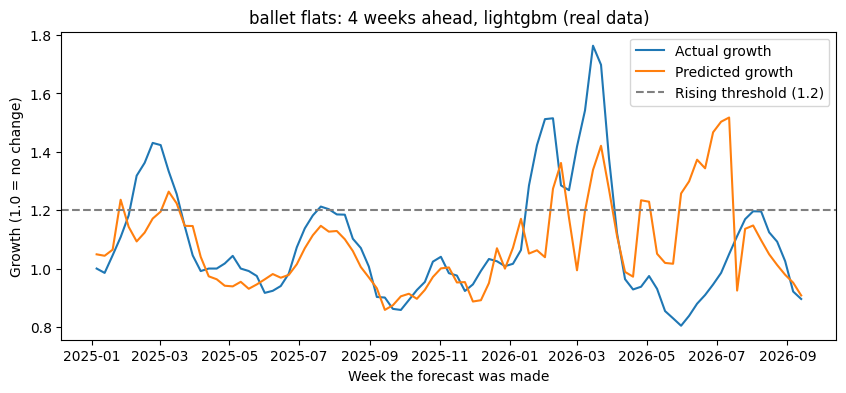

In [ ]:
style, horizon, model = "ballet flats", 4, "lightgbm"
one = df[(df["item"] == style) & (df["horizon"] == horizon) & (df["model"] == model)]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(one["origin"], one["actual_growth"], label="Actual growth")
ax.plot(one["origin"], one["predicted_growth"], label="Predicted growth")
ax.axhline(RISING_THRESHOLD, linestyle="--", color="grey", label=f"Rising threshold ({RISING_THRESHOLD})")
ax.set_title(f"{style}: {horizon} weeks ahead, {model} ({DATA_LABEL})")
ax.set_xlabel("Week the forecast was made")
ax.set_ylabel("Growth (1.0 = no change)")
ax.legend()
plt.show()